In [4]:
# NN：ニューラルネットワーク
import torch
import torch.nn as nn           # NNの部品（層・関数など）を作るための機能をまとめたパッケージ
import torch.optim as optim     # オプティマイザー
import matplotlib.pyplot as plt
import numpy as np

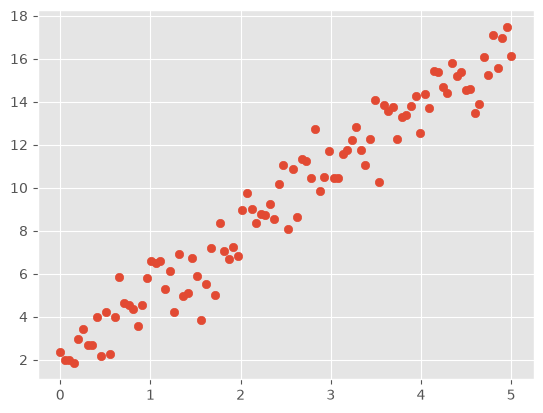

In [5]:
# データの生成
torch.manual_seed(123) # 毎回同じ乱数が出るように指定

a = 3
b = 2
x = torch.linspace(0, 5, 100).view(100, 1) # 100行1列の乱数配列を作成

eps = torch.randn(100, 1) # 100行1列の乱数配列を作成
y = a * x + b + eps

plt.scatter(x, y)

In [6]:
# モデルの定義
class LR(nn.Module): # nn.Module とは、PyTorchでNNのモデルを作るための土台となるクラス（継承してモデルを作る）
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1) # **_featuresは値の数
    def forward(self, x): # 順伝播
        output = self.linear(x)
        return output

In [7]:
# モデルの使用
model = LR()
x_test = torch.tensor([[1.0], [2.0]])
model(x_test) # 内部的に自作した forward メソッドを実行するようになっている（nn.Moduleの__call__参照）

tensor([[-0.6505],
        [-1.4166]], grad_fn=<AddmmBackward0>)

torch.Size([100, 1])


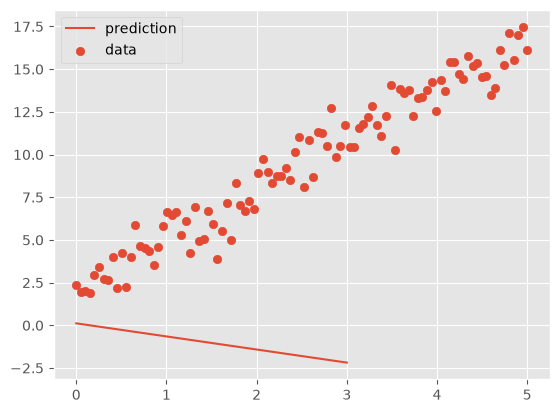

In [8]:
# 別のデータで計算してみる
x2 = torch.linspace(0, 3, 100).view(100, 1)
print(x2.size())
y_pred = model(x2)
plt.plot(x2, y_pred.detach(), label="prediction")
plt.scatter(x, y, label="data")
plt.legend()

In [9]:
# 最小2乗誤差（損失関数）
criterion = nn.MSELoss() 

# 確率的勾配効果法（重みとバイアスの情報を更新するために、引数として model.parameters() を渡しておく）
optimizer = optim.SGD(model.parameters(), lr=0.001)

In [10]:
losses = []
num_epoch = 500
for epoch in range(num_epoch):
    optimizer.zero_grad() # 勾配の初期化
    y_pred = model(x)
    loss = criterion(y_pred, y) # 予測値と正解のデータを渡す
    loss.backward() # 勾配を求める
    optimizer.step() # パラメータを更新（重み、バイアス）
    if epoch % 10 == 0:
        print("epoch: {}, loss: {}".format(epoch, loss.item()))
        losses.append(loss.item())

epoch: 0, loss: 156.7843017578125
epoch: 10, loss: 108.7425765991211
epoch: 20, loss: 75.5283203125
epoch: 30, loss: 52.565086364746094
epoch: 40, loss: 36.68894577026367
epoch: 50, loss: 25.712505340576172
epoch: 60, loss: 18.12348175048828
epoch: 70, loss: 12.876379013061523
epoch: 80, loss: 9.248371124267578
epoch: 90, loss: 6.73973274230957
epoch: 100, loss: 5.004983901977539
epoch: 110, loss: 3.805264472961426
epoch: 120, loss: 2.9754467010498047
epoch: 130, loss: 2.401364326477051
epoch: 140, loss: 2.00408935546875
epoch: 150, loss: 1.7290531396865845
epoch: 160, loss: 1.5385338068008423
epoch: 170, loss: 1.4064480066299438
epoch: 180, loss: 1.3147622346878052
epoch: 190, loss: 1.2510119676589966
epoch: 200, loss: 1.2065789699554443
epoch: 210, loss: 1.1755023002624512
epoch: 220, loss: 1.1536643505096436
epoch: 230, loss: 1.1382170915603638
epoch: 240, loss: 1.127191185951233
epoch: 250, loss: 1.1192246675491333
epoch: 260, loss: 1.1133768558502197
epoch: 270, loss: 1.1089966297

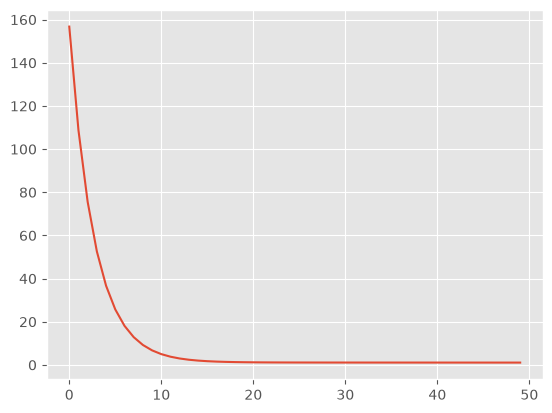

In [11]:
plt.plot(losses)

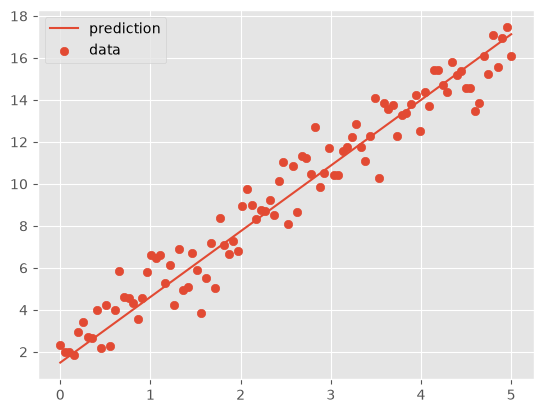

In [12]:
x_test = torch.linspace(0, 5, 100).view(100, 1)
y_test = model(x_test)
plt.plot(x_test, y_test.detach(), label="prediction")
plt.scatter(x, y, label="data")
plt.legend()